Sentiment Analysis:

Perform sentiment analysis on the recipe dataset (see link below) using different classification algorithms.

In [3]:
import numpy as np
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [4]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset
dataset = fetch_ucirepo(id=911)
# metadata
print(dataset.metadata)
# variable information
print(dataset.variables)

# Get the full dataset as a pandas DataFrame
df = dataset.data.original
display(df.head())

df = df.dropna(subset=["text", "stars"])
df = df[df["stars"].isin([1, 2, 4, 5])].copy()
print(df)
df["label"] = df["stars"].apply(lambda x: 1 if x >= 4 else 0)
print(f"Dataset successfully loaded. Final shape for analysis: {df.shape}")
print(df["label"].value_counts(normalize=True))
train_texts, test_texts, y_train, y_test = train_test_split(df["text"].values, df["label"].values, test_size=0.2, random_state=13)

{'uci_id': 911, 'name': 'Recipe Reviews and User Feedback', 'repository_url': 'https://archive.ics.uci.edu/dataset/911/recipe+reviews+and+user+feedback+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/911/data.csv', 'abstract': 'The "Recipe Reviews and User Feedback Dataset" is a comprehensive repository of data encompassing various aspects of recipe reviews and user interactions. It includes essential information such as the recipe name, its ranking on the top 100 recipes list, a unique recipe code, and user details like user ID, user name, and an internal user reputation score.\n\nEach review comment is uniquely identified with a comment ID and comes with additional attributes, including the creation timestamp, reply count, and the number of up-votes and down-votes received. Users\' sentiment towards recipes is quantified on a 1 to 5 star rating scale, with a score of 0 denoting an absence of rating.\n\nThis dataset is a valuable resource for researchers and data scie

,num_records,recipe_number,recipe_code,recipe_name,comment_id,user_id,user_name,user_reputation,created_at,reply_count,thumbs_up,thumbs_down,stars,best_score,text
0,0,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2G3aneMRgRMZwXqIHmSdXSG1hEM,u_9iFLIhMa8QaG,Jeri326,1,1665619889,0,0,0,5,527,"I tweaked it a little, removed onions because ..."
1,1,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FsPC83HtzCsQAtOxlbL6RcaPbY,u_Lu6p25tmE77j,Mark467,50,1665277687,0,7,0,5,724,Bush used to have a white chili bean and it ma...
2,2,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2FPrSGyTv7PQkZq37j92r9mYGkP,u_s0LwgpZ8Jsqq,Barbara566,10,1664404557,0,3,0,5,710,I have a very complicated white chicken chili ...
3,3,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DzdSIgV9qNiuBaLoZ7JQaartoC,u_fqrybAdYjgjG,jeansch123,1,1661787808,2,2,0,0,581,"In your introduction, you mentioned cream chee..."
4,4,1,14299,Creamy White Chili,sp_aUSaElGf_14299_c_2DtZJuRQYeTFwXBoZRfRhBPEXjI,u_XXWKwVhKZD69,camper77,10,1664913823,1,7,0,0,820,Wonderful! I made this for a &#34;Chili/Stew&#...


       num_records  recipe_number  recipe_code                    recipe_name  \
0                0              1        14299             Creamy White Chili   
1                1              1        14299             Creamy White Chili   
2                2              1        14299             Creamy White Chili   
5                5              1        14299             Creamy White Chili   
6                6              1        14299             Creamy White Chili   
...            ...            ...          ...                            ...   
18177          114            100        82745  Mamaw Emily’s Strawberry Cake   
18178          115            100        82745  Mamaw Emily’s Strawberry Cake   
18179          116            100        82745  Mamaw Emily’s Strawberry Cake   
18180          117            100        82745  Mamaw Emily’s Strawberry Cake   
18181          118            100        82745  Mamaw Emily’s Strawberry Cake   

                           

In [5]:
from collections import Counter

def tokenize(text):
  return re.findall(r"\b\w+\b",str(text).lower())
print("\nStep 2&3:Tokenizing  text and building Vocabulary...")
all_tokens=[]
for text in train_texts:
  all_tokens.extend(tokenize(text))

word_counts=Counter(all_tokens)

vocab={}
idx=0

for word, count in word_counts.most_common():
  if count>=4:
    vocab[word]=idx
    idx+=1

print(f"Vocabulary complete.Unique tokens retained:{len(vocab)}")
print(word_counts)


def text_to_vector(text,vocab):
  vector=[0]*len(vocab)
  for token in tokenize(text):
    if token in vocab:
      vector[vocab[token]]=1
  return vector

print("vectorizing text samples using manual binary encoding")
X_train=[text_to_vector(t,vocab) for t in train_texts]
X_test=[text_to_vector(t,vocab) for t in test_texts]
X_train=np.array(X_train)
X_test=np.array(X_test)
print(X_train.shape,X_test.shape)


Step 2&3:Tokenizing  text and building Vocabulary...
Vocabulary complete.Unique tokens retained:3744
Counter({'i': 24188, 'the': 20750, 'and': 17592, 'it': 15740, 'a': 12248, 'this': 11402, 'to': 9988, 'of': 8496, 'for': 7209, 'recipe': 7156, '39': 6936, 'was': 5881, 'my': 5843, 'is': 5842, 'in': 4587, 'made': 4439, 'make': 4286, 'so': 3826, 'with': 3816, 'have': 3408, 'used': 3161, 't': 3078, 'but': 2848, 'good': 2603, 'as': 2585, 'will': 2554, 'that': 2529, 'very': 2453, 'delicious': 2399, 'on': 2314, 'time': 2298, 'great': 2194, 's': 2168, 'easy': 2138, 'you': 2063, 'added': 2062, '1': 2040, 'out': 2026, 'again': 2024, 'not': 2005, 'just': 1889, 'family': 1886, 'one': 1805, 'use': 1776, 'we': 1763, 'like': 1697, 'also': 1676, 'loved': 1676, 'be': 1667, 'had': 1588, '2': 1582, 'they': 1498, 'all': 1461, 'cake': 1441, 'them': 1440, 'love': 1432, 'more': 1423, 'did': 1416, 'some': 1316, 'instead': 1315, 'soup': 1313, 'can': 1308, 'add': 1307, 'these': 1256, 'chicken': 1249, 'only': 12

....Logistic regression model....
Overall Accuracy: 0.9787

              precision    recall  f1-score   support

Negative (0)       0.63      0.40      0.49        82
Positive (1)       0.98      0.99      0.99      3117

    accuracy                           0.98      3199
   macro avg       0.81      0.70      0.74      3199
weighted avg       0.98      0.98      0.98      3199

Confusion Matrix:
[[  33   49]
 [  19 3098]]


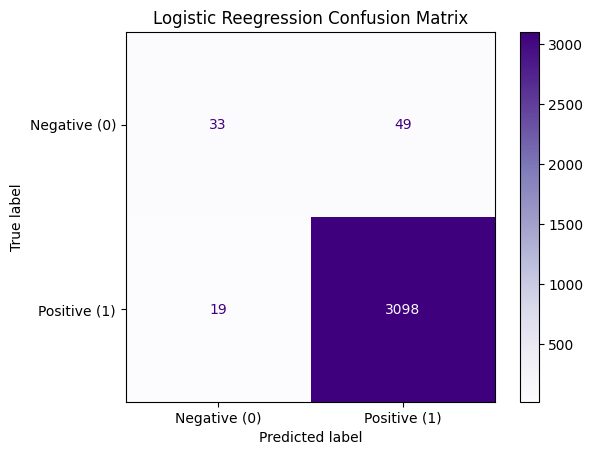

In [6]:
#Implement Logistic regression
from sklearn.linear_model import LogisticRegression
print("....Logistic regression model....")
model=LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the raw matrix values
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])
disp.plot(cmap=plt.cm.Purples)
plt.title('Logistic Reegression Confusion Matrix')
plt.show()

=== Naive Bayes Classifier Performance ===
Overall Accuracy: 0.9728

              precision    recall  f1-score   support

Negative (0)       0.47      0.41      0.44        82
Positive (1)       0.98      0.99      0.99      3117

    accuracy                           0.97      3199
   macro avg       0.73      0.70      0.71      3199
weighted avg       0.97      0.97      0.97      3199

Confusion Matrix:
[[  34   48]
 [  39 3078]]


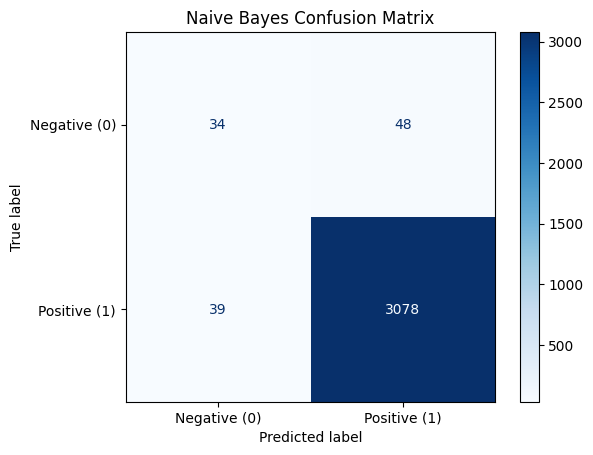

In [7]:
#Implement Naive-Bayes model

from sklearn.naive_bayes import MultinomialNB

# Initialize and train the Naive Bayes model
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = nb_classifier.predict(X_test)

# Output performance metrics
print("=== Naive Bayes Classifier Performance ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the raw matrix values
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Naive Bayes Confusion Matrix')
plt.show()

=== Decision Tree Classifier Performance ===
Overall Accuracy: 0.9553

              precision    recall  f1-score   support

Negative (0)       0.18      0.21      0.19        82
Positive (1)       0.98      0.97      0.98      3117

    accuracy                           0.96      3199
   macro avg       0.58      0.59      0.58      3199
weighted avg       0.96      0.96      0.96      3199

Confusion Matrix:
[[  17   65]
 [  78 3039]]


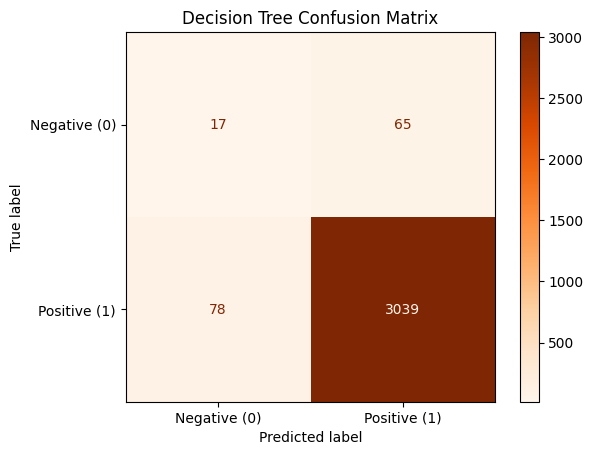

In [8]:
#Implement Decision tree
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the Decision Tree classifier
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred_dt = dt_classifier.predict(X_test)

# Output performance metrics
print("=== Decision Tree Classifier Performance ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}\n")
print(classification_report(y_test, y_pred_dt, target_names=['Negative (0)', 'Positive (1)']))

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

# Print the raw matrix values
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])
disp.plot(cmap=plt.cm.Oranges)
plt.title('Decision Tree Confusion Matrix')
plt.show()